# Cat breed classifier
Train our own breed classifier and compare it with CLIP / ResNet. Plan: `CLASSIFIER_PLAN.md`.

## Step 1: data

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import torch
from PIL import Image
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms

RAW = Path("../data/_raw/oxford-iiit-pet")
IMG_SIZE = 64
BATCH_SIZE = 32

### Split
Each annotation line is `name class_id species breed_id`; species 1 = cat.

We use the dataset's official split so our numbers are comparable to others, and because the 102 library images come from `trainval`: scoring on `test` keeps the comparison honest.

In [2]:
def read_split(name):
    rows = []
    for line in (RAW / "annotations" / name).read_text().splitlines():
        stem, _, species, _ = line.split()
        if species == "1":
            rows.append(stem)
    return rows


train_stems = read_split("trainval.txt")
test_stems = read_split("test.txt")

breeds = sorted({s.rsplit("_", 1)[0] for s in train_stems})
breed_to_idx = {b: i for i, b in enumerate(breeds)}

len(train_stems), len(test_stems), breeds

(1188,
 1183,
 ['Abyssinian',
  'Bengal',
  'Birman',
  'Bombay',
  'British_Shorthair',
  'Egyptian_Mau',
  'Maine_Coon',
  'Persian',
  'Ragdoll',
  'Russian_Blue',
  'Siamese',
  'Sphynx'])

### Dataset and DataLoader
- **`Dataset`**: knows *how to get one example*. It only needs `__len__` and `__getitem__`. Images are loaded lazily, so memory stays small.
- **`DataLoader`**: wraps a dataset and serves *batches*, shuffled for training. Shuffling stops the model from learning the order (all Abyssinians first, ...).
- **`transform`**: turns a PIL image into a tensor. Every image must have the same shape to stack into a batch, hence `Resize`.

In [3]:
class CatDataset(Dataset):
    def __init__(self, stems, transform):
        self.stems = stems
        self.transform = transform

    def __len__(self):
        return len(self.stems)

    def __getitem__(self, i):
        stem = self.stems[i]
        image = Image.open(RAW / "images" / f"{stem}.jpg").convert("RGB")
        label = breed_to_idx[stem.rsplit("_", 1)[0]]
        return self.transform(image), label

In [4]:
transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),  # PIL (H, W, C) 0-255 -> tensor (C, H, W) 0-1
])

train_ds = CatDataset(train_stems, transform)
test_ds = CatDataset(test_stems, transform)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE)

images, labels = next(iter(train_loader))
images.shape, labels.shape

(torch.Size([32, 3, 64, 64]), torch.Size([32]))

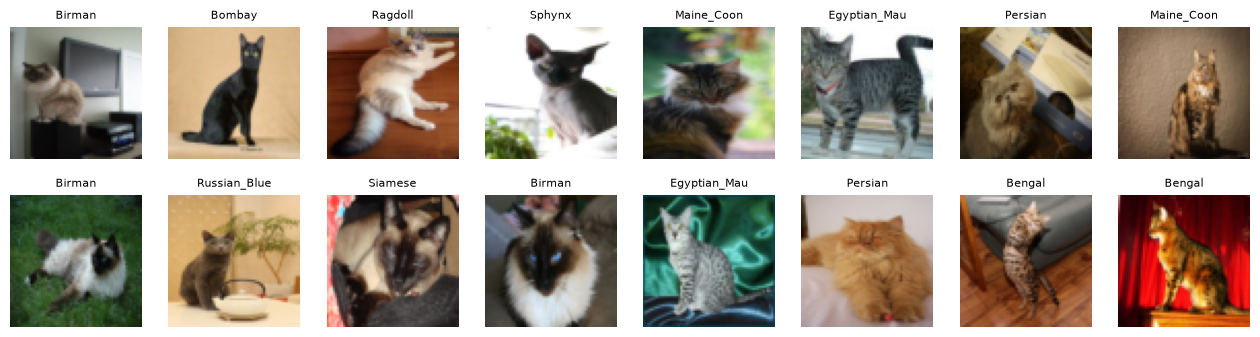

In [5]:
fig, axes = plt.subplots(2, 8, figsize=(16, 4))
for ax, image, label in zip(axes.flat, images, labels):
    ax.imshow(image.permute(1, 2, 0))  # (C, H, W) -> (H, W, C) for matplotlib
    ax.set_title(breeds[label], fontsize=8)
    ax.axis("off")

## Step 2: tiny CNN from scratch

### Validation split
`test` is reserved for the final comparison. While training we need a third set to watch for overfitting and to tune choices against: **validation**, carved out of `trainval`. Tuning on `test` would make its score optimistic.

In [6]:
from torch.utils.data import random_split

torch.manual_seed(0)
train_part, val_part = random_split(train_ds, [0.8, 0.2])

train_loader = DataLoader(train_part, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_part, batch_size=BATCH_SIZE)

len(train_part), len(val_part)

(951, 237)

### The model
A CNN is a stack of small, learned filters:
- **`Conv2d`** slides 3×3 filters over the image. Early filters pick up edges and colours; deeper ones combine those into textures and shapes (fur pattern, ear shape).
- **`ReLU`** adds non-linearity. Without it, stacked layers collapse into one linear map.
- **`MaxPool2d(2)`** halves height and width: cheaper, and each later filter "sees" a larger part of the image.
- **`Linear`** at the end maps the features to **12 scores (logits)**, one per breed.

Shapes through the network, for one image:

| layer | output shape |
|---|---|
| input | 3 × 64 × 64 |
| conv(3→16) + relu + pool | 16 × 32 × 32 |
| conv(16→32) + relu + pool | 32 × 16 × 16 |
| conv(32→64) + relu + pool | 64 × 8 × 8 |
| flatten | 4096 |
| linear(4096→12) | 12 |

**Your turn:** fill in `TinyCNN`. Hints: `nn.Conv2d(in, out, kernel_size=3, padding=1)` keeps height/width the same; `nn.Sequential` chains layers; `nn.Flatten()` turns `64×8×8` into `4096`.

In [7]:
from torch import nn


class TinyCNN(nn.Module):
    def __init__(self, n_classes=len(breeds)):
        super().__init__()
        self.features = nn.Sequential(nn.Conv2d(3, 16, kernel_size = 3, padding = 1), nn.ReLU(), nn.MaxPool2d(2),
                                      nn.Conv2d(16, 32, kernel_size = 3, padding = 1), nn.ReLU(), nn.MaxPool2d(2),
                                      nn.Conv2d(32, 64, kernel_size = 3, padding = 1), nn.ReLU(), nn.MaxPool2d(2))
        self.head = nn.Sequential(nn.Flatten(), nn.Linear(64*8*8, n_classes))

    def forward(self, x):
        x = self.features(x)
        return self.head(x)

Sanity check: one batch in, `[32, 12]` out. Checking shapes before training saves a lot of debugging.

In [8]:
model = TinyCNN()
n_params = sum(p.numel() for p in model.parameters())
model(images).shape, n_params

(torch.Size([32, 12]), 72748)

### Loss, optimizer, training loop
- **Loss: `CrossEntropyLoss`**. Softmax turns the 12 logits into probabilities; the loss is `-log(p of the correct breed)`. Confident and right → near 0; confident and wrong → large. Random guessing gives `log(12) ≈ 2.48`, a useful number to see at the start.
- **Optimizer: `Adam`**. Uses the gradients to nudge every weight. `lr` (learning rate) sets the step size.
- **One training step** is always the same 4 lines:
  1. `optimizer.zero_grad()`: clear old gradients (PyTorch adds them up by default)
  2. `loss = loss_fn(model(x), y)`: forward pass
  3. `loss.backward()`: compute gradients (backprop)
  4. `optimizer.step()`: update weights
- `model.train()` / `model.eval()` switch layers like dropout and batchnorm between modes (none yet, but a good habit). `torch.no_grad()` skips gradient bookkeeping during evaluation.

In [9]:
def train_one_epoch(model, loader, loss_fn, optimizer):
    model.train()
    total_loss, correct, n = 0.0, 0, 0
    for x, y in loader:
        optimizer.zero_grad()
        logits = model(x)
        loss = loss_fn(logits, y)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * len(y)
        correct += (logits.argmax(1) == y).sum().item()
        n += len(y)
    return total_loss / n, correct / n


@torch.no_grad()
def evaluate(model, loader, loss_fn):
    model.eval()
    total_loss, correct, n = 0.0, 0, 0
    for x, y in loader:
        logits = model(x)
        total_loss += loss_fn(logits, y).item() * len(y)
        correct += (logits.argmax(1) == y).sum().item()
        n += len(y)
    return total_loss / n, correct / n

### Train
An **epoch** is one pass over all training images. Expect about 5 s per epoch on CPU.

In [10]:
torch.manual_seed(0)
model = TinyCNN()
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

EPOCHS = 15
history = []
for epoch in range(EPOCHS):
    train_loss, train_acc = train_one_epoch(model, train_loader, loss_fn, optimizer)
    val_loss, val_acc = evaluate(model, val_loader, loss_fn)
    history.append((train_loss, val_loss, train_acc, val_acc))
    print(f"{epoch:2d}  train {train_loss:.2f} / {train_acc:.2f}   val {val_loss:.2f} / {val_acc:.2f}")

 0  train 2.47 / 0.12   val 2.46 / 0.12
 1  train 2.27 / 0.21   val 2.38 / 0.12
 2  train 2.07 / 0.30   val 2.31 / 0.18
 3  train 1.93 / 0.34   val 2.29 / 0.23
 4  train 1.76 / 0.40   val 2.23 / 0.22
 5  train 1.62 / 0.46   val 2.26 / 0.23
 6  train 1.49 / 0.50   val 2.19 / 0.25
 7  train 1.37 / 0.54   val 2.33 / 0.24
 8  train 1.22 / 0.58   val 2.35 / 0.30
 9  train 1.10 / 0.66   val 2.45 / 0.27
10  train 0.96 / 0.69   val 2.74 / 0.23
11  train 0.84 / 0.73   val 2.83 / 0.27
12  train 0.69 / 0.78   val 3.01 / 0.25
13  train 0.50 / 0.85   val 3.04 / 0.29
14  train 0.42 / 0.88   val 3.50 / 0.27


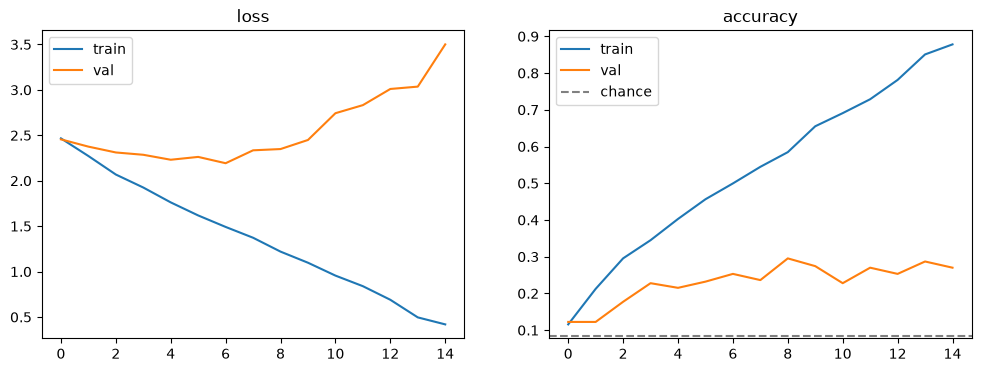

In [12]:
train_loss, val_loss, train_acc, val_acc = zip(*history)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(train_loss, label="train")
ax1.plot(val_loss, label="val")
ax1.set_title("loss")
ax1.legend()
ax2.plot(train_acc, label="train")
ax2.plot(val_acc, label="val")
ax2.axhline(1 / len(breeds), color="grey", linestyle="--", label="chance")
ax2.set_title("accuracy")
ax2.legend()

### What to look for
- Loss starts near `2.48`? Then the model starts out guessing, as it should.
- **Train accuracy keeps climbing while val stalls or val loss rises → overfitting**: the model memorises these ~950 images instead of learning breeds. That is the problem step 3 tackles.
- Note the best val accuracy in the log in `CLASSIFIER_PLAN.md`.

## Step 3: fight overfitting

### Diagnosis from step 2
Train accuracy climbed to ~0.88 while val got stuck around 0.25–0.30, and val loss started *rising* after ~6 epochs. The model memorises the 951 training images (72k weights is plenty for that) instead of learning what makes a breed.

Three standard fixes, added **one at a time** so we can see what each one contributes:
1. **Data augmentation**: make memorising impossible
2. **Batch normalisation**: make training more stable
3. **Dropout**: stop the model from leaning on a few features

First, wrap training into a function so each experiment is one line.

In [11]:
def fit(model, train_loader, epochs, lr=1e-3):
    loss_fn = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    history = []
    for epoch in range(epochs):
        train_loss, train_acc = train_one_epoch(model, train_loader, loss_fn, optimizer)
        val_loss, val_acc = evaluate(model, val_loader, loss_fn)
        history.append((train_loss, val_loss, train_acc, val_acc))
        print(f"{epoch:2d}  train {train_loss:.2f} / {train_acc:.2f}   val {val_loss:.2f} / {val_acc:.2f}")
    return history


def plot_runs(runs):
    """runs: {name: history}. Solid = val, dashed = train."""
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4))
    for name, hist in runs.items():
        train_loss, val_loss, train_acc, val_acc = zip(*hist)
        line, = ax1.plot(val_loss, label=name)
        ax1.plot(train_loss, "--", color=line.get_color(), alpha=0.5)
        ax2.plot(val_acc, color=line.get_color(), label=name)
        ax2.plot(train_acc, "--", color=line.get_color(), alpha=0.5)
    ax2.axhline(1 / len(breeds), color="grey", linestyle=":", label="chance")
    ax1.set_title("loss")
    ax2.set_title("accuracy")
    ax2.legend()


runs = {"baseline": history}  # the step 2 run

### 3a. Data augmentation
Every epoch, show each training image with a **random variation**: a slightly different crop, mirrored, a bit brighter. The model never sees the exact same pixels twice, so memorising stops paying off; what stays constant across variations is the breed.

Rule: an augmentation must **keep the label true**. A mirrored Persian is still a Persian. Upside-down would be legal but unrealistic (photos are rarely upside down), so it wastes capacity.

**Your turn:** write `train_transform`. It must end with `ToTensor()` and produce `IMG_SIZE × IMG_SIZE` images. Pick 2–3 from:
- `transforms.RandomResizedCrop(IMG_SIZE, scale=(0.6, 1.0))`: random crop covering 60–100% of the image, resized to `IMG_SIZE`. It replaces `Resize`.
- `transforms.RandomHorizontalFlip()`: mirror with 50% chance
- `transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2)`: lighting variation
- `transforms.RandomRotation(15)`: tilt up to ±15°

Careful with colour: for some breeds colour *is* the signal (Russian Blue is grey-blue). Strong `hue` jitter would turn it into a different-looking cat.

In [12]:
train_transform = transforms.Compose([
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.6, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ToTensor(),
])

Check: the same image, 8 times through `train_transform`. Every version should still clearly be the same cat.

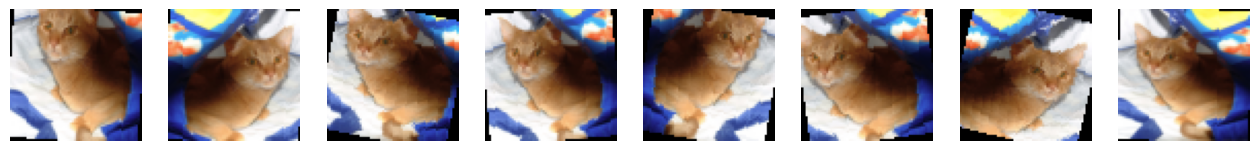

In [13]:
sample = Image.open(RAW / "images" / f"{train_stems[0]}.jpg").convert("RGB")

fig, axes = plt.subplots(1, 8, figsize=(16, 2.5))
for ax in axes:
    ax.imshow(train_transform(sample).permute(1, 2, 0))
    ax.axis("off")

**Gotcha:** `random_split` returns two *views* on the same `train_ds`, so they share one transform. Setting augmentation on it would also augment the validation images, and then val accuracy no longer measures the real task.

Fix: keep the same split (the indices), but build two datasets with their own transform. Validation and test always get the plain `transform`.

In [14]:
train_aug_ds = CatDataset([train_stems[i] for i in train_part.indices], train_transform)
val_ds = CatDataset([train_stems[i] for i in val_part.indices], transform)

train_aug_loader = DataLoader(train_aug_ds, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE)  # same images as before, now explicit

len(train_aug_ds), len(val_ds)

(951, 237)

Same `TinyCNN`, only the data changed. Augmentation makes the task harder, so learning is slower: train for 30 epochs instead of 15 (~3 min).

 0  train 2.47 / 0.12   val 2.46 / 0.12
 1  train 2.32 / 0.21   val 2.43 / 0.12
 2  train 2.21 / 0.24   val 2.38 / 0.21
 3  train 2.14 / 0.26   val 2.35 / 0.17
 4  train 2.04 / 0.28   val 2.25 / 0.18
 5  train 1.98 / 0.34   val 2.23 / 0.19
 6  train 1.90 / 0.34   val 2.20 / 0.23
 7  train 1.88 / 0.35   val 2.11 / 0.26
 8  train 1.81 / 0.38   val 2.13 / 0.23
 9  train 1.77 / 0.39   val 2.09 / 0.25
10  train 1.74 / 0.40   val 2.07 / 0.24
11  train 1.74 / 0.41   val 2.07 / 0.27
12  train 1.70 / 0.41   val 2.27 / 0.22
13  train 1.73 / 0.41   val 2.14 / 0.24
14  train 1.65 / 0.42   val 2.04 / 0.28
15  train 1.61 / 0.45   val 2.03 / 0.31
16  train 1.61 / 0.45   val 2.03 / 0.29
17  train 1.57 / 0.46   val 2.00 / 0.29
18  train 1.56 / 0.45   val 1.94 / 0.34
19  train 1.53 / 0.48   val 1.94 / 0.34
20  train 1.48 / 0.49   val 2.01 / 0.28
21  train 1.51 / 0.47   val 1.95 / 0.30
22  train 1.52 / 0.49   val 2.09 / 0.26
23  train 1.42 / 0.53   val 1.95 / 0.35
24  train 1.42 / 0.51   val 2.02 / 0.31


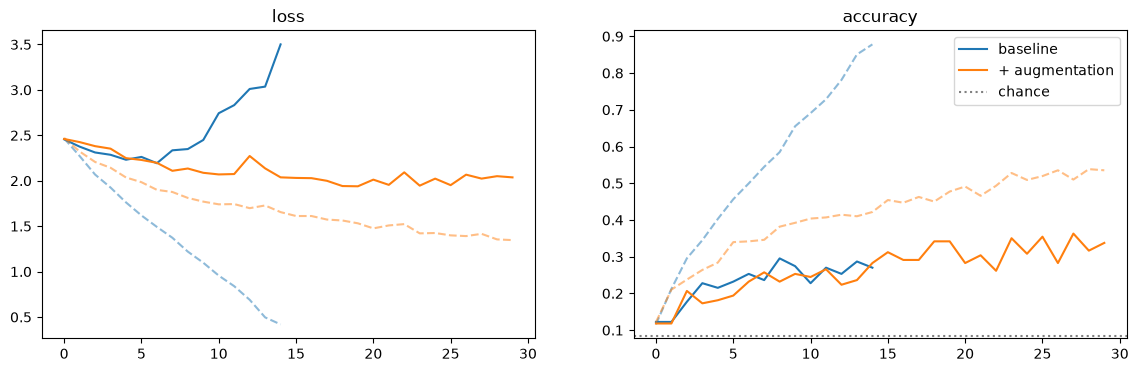

In [19]:
torch.manual_seed(0)
runs["+ augmentation"] = fit(TinyCNN(), train_aug_loader, epochs=30)
plot_runs(runs)

### 3b. Batch normalisation + dropout
**`BatchNorm2d(channels)`**, placed after a conv: rescales each channel's outputs to mean 0 and std 1 over the batch, then applies a learned scale and shift. Without it, the scale of a layer's output drifts as the layers before it change, and every layer keeps chasing a moving target. With it, training is more stable and tolerates higher learning rates. The batch-to-batch noise also gives a small regularising effect.

**`Dropout(p)`**: during training, sets a random fraction `p` of the values to 0 (and scales up the rest). The model can't rely on any single feature, so it has to spread the evidence over many: an ensemble effect. Typically placed in the head, just before the `Linear`.

Both behave differently in training and evaluation: this is where `model.train()` / `model.eval()` start to matter.

**Your turn:** write `TinyCNN2`:
- each block: conv → **batchnorm** → relu → pool
- head: flatten → **dropout(0.5)** → linear

Tip: three almost identical blocks invite copy-paste mistakes. A small helper `def block(c_in, c_out): return nn.Sequential(...)` keeps it readable.

In [15]:
def block(c_in, c_out):
    return nn.Sequential(
        nn.Conv2d(c_in, c_out, kernel_size=3, padding=1),
        nn.BatchNorm2d(c_out),
        nn.ReLU(),
        nn.MaxPool2d(2),
    )


class TinyCNN2(nn.Module):
    def __init__(self, n_classes=len(breeds)):
        super().__init__()
        self.features = nn.Sequential(
            block(3, 16), block(16, 32), block(32, 64)
        )
        self.head = nn.Sequential(
            nn.Flatten(), nn.Dropout(0.5), nn.Linear(64 * 8 * 8, n_classes)
        )

    def forward(self, x):
        x = self.features(x)
        return self.head(x)

In [16]:
model = TinyCNN2()
model(images).shape, sum(p.numel() for p in model.parameters())

(torch.Size([32, 12]), 72972)

 0  train 2.76 / 0.15   val 2.61 / 0.16
 1  train 2.19 / 0.28   val 2.44 / 0.20
 2  train 2.13 / 0.29   val 2.31 / 0.22
 3  train 2.03 / 0.33   val 2.14 / 0.26
 4  train 1.98 / 0.34   val 2.34 / 0.26
 5  train 1.89 / 0.39   val 2.27 / 0.30
 6  train 1.83 / 0.39   val 2.20 / 0.25
 7  train 1.78 / 0.40   val 3.38 / 0.20
 8  train 1.79 / 0.40   val 2.10 / 0.31
 9  train 1.79 / 0.40   val 2.30 / 0.27
10  train 1.69 / 0.42   val 2.12 / 0.29
11  train 1.60 / 0.46   val 2.37 / 0.28
12  train 1.57 / 0.48   val 2.12 / 0.30
13  train 1.57 / 0.47   val 2.09 / 0.32
14  train 1.56 / 0.45   val 2.21 / 0.30
15  train 1.48 / 0.50   val 2.06 / 0.28
16  train 1.58 / 0.46   val 1.97 / 0.34
17  train 1.52 / 0.48   val 2.15 / 0.32
18  train 1.43 / 0.51   val 1.92 / 0.34
19  train 1.39 / 0.52   val 2.20 / 0.27
20  train 1.33 / 0.54   val 1.87 / 0.35
21  train 1.37 / 0.51   val 2.11 / 0.32
22  train 1.44 / 0.52   val 1.94 / 0.38
23  train 1.31 / 0.54   val 1.96 / 0.36
24  train 1.28 / 0.56   val 2.10 / 0.32


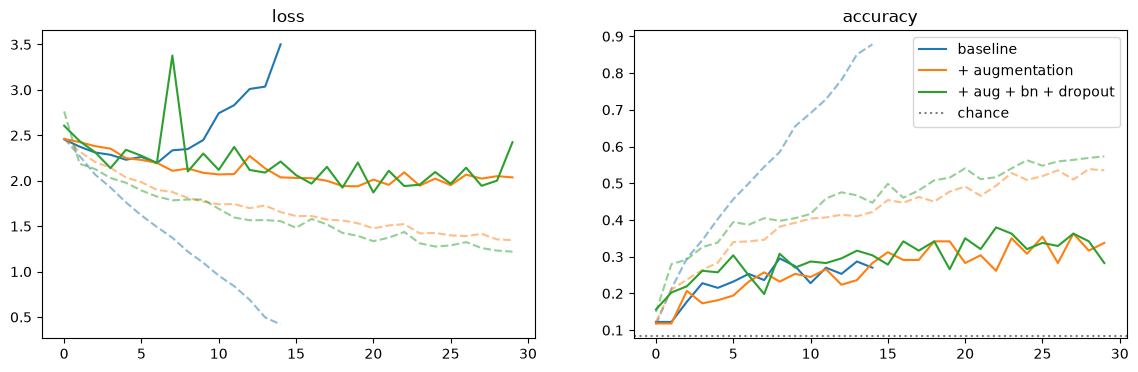

In [26]:
torch.manual_seed(0)
runs["+ aug + bn + dropout"] = fit(TinyCNN2(), train_aug_loader, epochs=30)
plot_runs(runs)

### What to look for
- Is the **gap** between dashed (train) and solid (val) smaller than in the baseline? That gap *is* overfitting.
- Train accuracy is now probably *lower* than in the baseline, while val is higher. Why is that a good sign?
- Is val still rising at epoch 30? Then more epochs would help; if it's flat, the model has hit its ceiling.
- Log the best val accuracy of each run in `CLASSIFIER_PLAN.md`.

Even with all three fixes, a small CNN trained on ~950 images ends up well below what CLIP does. Step 4 shows why: the problem isn't the tricks, it's the amount of data.

## Step 4: transfer learning

### Why the small CNN hits a ceiling
From scratch, ~950 images must teach the model *everything*: what an edge is, what fur is, what an ear is, and only then which breed it is. That's far too little data.

**ResNet18** was already trained on ImageNet: 1.2M images, 1000 classes (including a few cat breeds). Its layers learned a hierarchy we can reuse:
- early layers: edges, colours, textures (useful for any image)
- later layers: object parts like eyes, ears, fur patterns
- final `fc` layer: maps 512 features to ImageNet's 1000 classes (useless for us)

Plan: keep everything except `fc`, and put our own 12-breed head on top.

This is the same network as the `resnet18` backend in your index (`embed.py`). The index uses the 512 features *with `fc` removed* as embeddings.

In [17]:
from torchvision import models

resnet = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
[name for name, _ in resnet.named_children()], resnet.fc

(['conv1',
  'bn1',
  'relu',
  'maxpool',
  'layer1',
  'layer2',
  'layer3',
  'layer4',
  'avgpool',
  'fc'],
 Linear(in_features=512, out_features=1000, bias=True))

### Preprocessing must match pretraining
The pretrained weights expect inputs that look like what they saw during training:
- **224 × 224** images
- **normalised per colour channel** with ImageNet's mean and std: `(x - mean) / std`. The first conv layer's weights were tuned to inputs centred around 0. Feeding raw 0–1 values shifts every activation, and the learned features stop working.

**Your turn:** write both transforms. Order matters: `Normalize` works on tensors, so it comes *after* `ToTensor()`.
- `tl_train_transform`: `RandomResizedCrop(224, scale=(0.6, 1.0))`, horizontal flip, `ToTensor`, `Normalize`
- `tl_eval_transform` (no randomness): `Resize(256)`, `CenterCrop(224)`, `ToTensor`, `Normalize`. This is the standard ImageNet evaluation recipe: resize the short side, then cut out the centre.

Use `transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)`.

In [18]:
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

tl_train_transform = transforms.Compose(
    [
        transforms.RandomResizedCrop(224, scale=(0.6, 1.0)),
        transforms.RandomHorizontalFlip(),
        transforms.ToTensor(),
        transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
    ]
)
tl_eval_transform = transforms.Compose(
    [
        transforms.Resize(256),
        transforms.CenterCrop(224),
        transforms.ToTensor(),
        transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
    ]
)

Same split as before, new transforms. Note: `fit()` evaluates on the global `val_loader`, so we point it at the 224 version.

In [19]:
tl_train_ds = CatDataset([train_stems[i] for i in train_part.indices], tl_train_transform)
tl_val_ds = CatDataset([train_stems[i] for i in val_part.indices], tl_eval_transform)

tl_train_loader = DataLoader(tl_train_ds, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(tl_val_ds, batch_size=BATCH_SIZE)

x, _ = next(iter(tl_train_loader))
x.shape, x.mean().item(), x.std().item()  # expect [32, 3, 224, 224], mean ≈ 0, std ≈ 1

(torch.Size([32, 3, 224, 224]), -0.012827279977500439, 1.1810228824615479)

### Freeze the backbone, replace the head
- **Freezing**: `param.requires_grad = False` means no gradient is computed for that weight, so the optimizer never changes it. Training gets cheaper, and the pretrained features stay intact.
- **New head**: `nn.Linear(512, n_classes)` replaces `fc`. A freshly created layer has `requires_grad=True` by default, so it's the only part that learns.

**Your turn:** write `make_resnet()`: load the pretrained ResNet18, freeze all its parameters, replace `model.fc`, return the model. The order matters: freeze first, then add the new head.

In [31]:
def make_resnet(n_classes=len(breeds)):
    resnet = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)

    for param in resnet.parameters():
        param.requires_grad = False

    resnet.fc = nn.Linear(resnet.fc.in_features, n_classes)

    return resnet

Check: only the head should be trainable, i.e. 512 × 12 weights + 12 biases = **6,156** out of ~11M.

In [32]:
def count_params(model):
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    total = sum(p.numel() for p in model.parameters())
    return trainable, total


model_tl = make_resnet()
count_params(model_tl)

(6156, 11182668)

### 4a. Train the head only
6k weights instead of 72k, and 5 epochs instead of 30 (~4 min): the features are already good, so the head only has to learn which features point to which breed.

Side note: `model.train()` still puts the frozen backbone's BatchNorm layers in training mode, so their running mean and std adapt slightly to our cat images. Usually harmless; just know it happens.

In [33]:
torch.manual_seed(0)
model_tl = make_resnet()
runs["resnet18 head"] = fit(model_tl, tl_train_loader, epochs=5)

 0  train 2.04 / 0.35   val 1.43 / 0.65
 1  train 1.21 / 0.73   val 0.97 / 0.75
 2  train 0.84 / 0.83   val 0.76 / 0.81
 3  train 0.65 / 0.87   val 0.67 / 0.81
 4  train 0.56 / 0.88   val 0.57 / 0.84


### 4b. Fine-tune the last block
The head alone can only *recombine* ImageNet features. Unfreezing the last block (`layer4`, the most task-specific features) lets those features adapt to cat breeds.

Two rules:
- **Head first, then unfreeze.** A random head sends large, noisy gradients back; on a pretrained backbone those would damage the features. We already trained the head in 4a, so we continue from that model.
- **Lower learning rate (`1e-4` instead of `1e-3`).** We want to *nudge* pretrained weights, not overwrite them.

**Your turn:** unfreeze `model_tl.layer4`. Then check with `count_params(model_tl)`: trainable should jump to ~8.4M.

In [39]:
for param in model_tl.layer4.parameters():
    param.requires_grad = True

count_params(model_tl)

(8399884, 11182668)

~5 min: gradients now flow through `layer4` too.

 0  train 0.38 / 0.91   val 0.32 / 0.88
 1  train 0.16 / 0.97   val 0.31 / 0.88
 2  train 0.10 / 0.98   val 0.29 / 0.90
 3  train 0.06 / 0.99   val 0.30 / 0.89
 4  train 0.04 / 1.00   val 0.26 / 0.90


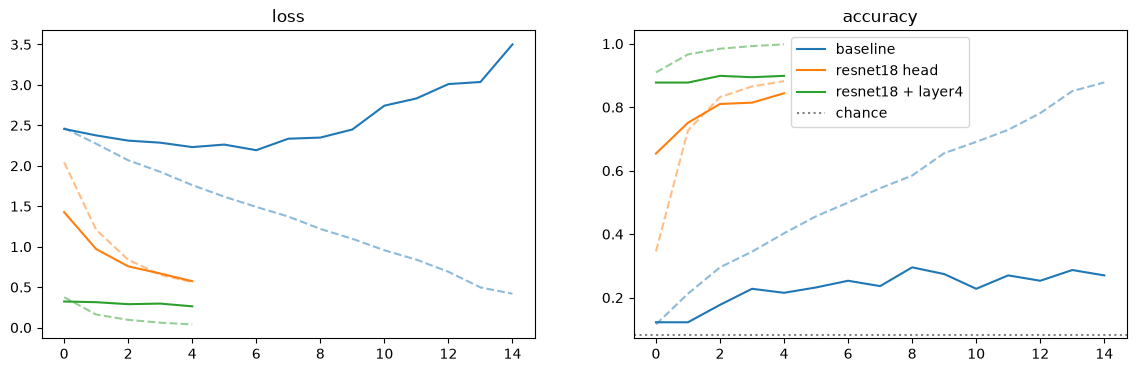

In [40]:
runs["resnet18 + layer4"] = fit(model_tl, tl_train_loader, epochs=5, lr=1e-4)
plot_runs(runs)

### What to look for
- How big is the jump from the best step 3 model to "resnet18 head"? That jump is what 1.2M pretraining images buy.
- Did fine-tuning `layer4` add anything on top? With ~950 training images and 8M trainable weights, overfitting is back on the table: watch the train/val gap.
- Log both in `CLASSIFIER_PLAN.md`.